# Day 1 EDA: what do students know, and where do they struggle?

**EDA (exploratory data analysis)** means looking carefully at data *before* building models,
like a doctor's check-up before treatment. We answer four questions from the brief:

1. **Accuracy per concept**: how often are answers right, per skill / lesson?
2. **Learning curves**: do students get better with practice?
3. **Dropout points**: when, and where in the course, do students quit?
4. **Hardest concepts**: which skills are really the hardest?

Every section follows the same pattern: **question → chart → table → INSIGHT** (one line).
The insight sentences are *computed from the numbers*, so they stay true if the data changes.

### Two datasets, never mixed in one number
| | What it is | What it can tell us |
|---|---|---|
| **real** | ASSISTments 2009-10: 4,163 real students, maths skills | real learning behaviour |
| **simulated** | 1,000 simulated students on *our* Python course | only what we built into the simulator; it tests the pipeline that will run on Ilm Academy's real logs |

Rebuild the data first if needed: `python -m ilm.learners.assistments` and `python -m ilm.learners.simulator`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "ilm").exists() else Path.cwd().parent  # run from notebooks/ or the root
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ilm import config
from ilm.analytics import eda
from ilm.content.download import all_lessons
from ilm.graph.concept_graph import load_concepts

pd.set_option("display.precision", 3)
FIG_DIR = config.REPORTS_DIR / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
INSIGHTS = []

def insight(section, text):
    INSIGHTS.append({"section": section, "insight": text})
    print("INSIGHT:", text)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

real = pd.read_csv(config.PROCESSED_DIR / "assistments" / "interactions.csv.gz")
sim = pd.read_csv(config.PROCESSED_DIR / "simulated" / "interactions.csv.gz")
people = pd.read_csv(config.PROCESSED_DIR / "simulated" / "students.csv")
qtruth = pd.read_csv(config.PROCESSED_DIR / "simulated" / "questions_truth.csv")
people = people[people["persona"].isna()]          # the 1,000 random students (not Ali/Sara)
sim = sim[sim["student_id"].isin(people["student_id"])]

lesson_title = {l["id"]: l["title"] for l in all_lessons()}
lesson_of = {c["id"]: c["taught_in"][0] for c in load_concepts()}
sim["lesson"] = sim["concept"].map(lesson_of)

pd.DataFrame({
    "answers": [len(real), len(sim)],
    "students": [real["user_id"].nunique(), sim["student_id"].nunique()],
    "skills / concepts": [real["skill"].nunique(), sim["concept"].nunique()],
    "accuracy": [real["correct"].mean(), sim["correct"].mean()],
}, index=["real (ASSISTments)", "simulated (our course)"])

,answers,students,skills / concepts,accuracy
real (ASSISTments),283105,4163,149,0.658
simulated (our course),106911,976,65,0.533


## 1. Accuracy per concept

**Accuracy** = right answers ÷ all answers.

**Why every accuracy gets an interval.** Flip a fair coin 4 times and get 3 heads: that is 75%,
but nobody believes the coin is a 75% coin. With few answers, accuracy is mostly luck. The
**95% interval** (we use the *Wilson* interval) is the range of accuracies that could easily
have produced what we saw. Narrow interval = trustworthy number. We also ignore any skill with
fewer than 200 answers.

In [2]:
skills = eda.accuracy_by(real, "skill_name")
below_half = (skills["accuracy"] < 0.5).sum()
print(f"{len(skills)} real skills with 200+ answers; accuracy from {skills['accuracy'].min():.0%} to {skills['accuracy'].max():.0%}")
display(skills["accuracy"].describe(percentiles=[.25, .5, .75]).to_frame().T)
insight("1 accuracy (real)",
        f"{below_half} of {len(skills)} maths skills are answered correctly less than half the time, "
        f"and the middle half of skills sits between {skills['accuracy'].quantile(.25):.0%} and "
        f"{skills['accuracy'].quantile(.75):.0%}: skills differ a lot in difficulty, so equal practice per skill "
        f"is likely too much for some and too little for others.")

112 real skills with 200+ answers; accuracy from 14% to 95%


,count,mean,std,min,25%,50%,75%,max
accuracy,112.0,0.656,0.147,0.14,0.591,0.66,0.758,0.95


INSIGHT: 15 of 112 maths skills are answered correctly less than half the time, and the middle half of skills sits between 59% and 76%: skills differ a lot in difficulty, so equal practice per skill is likely too much for some and too little for others.


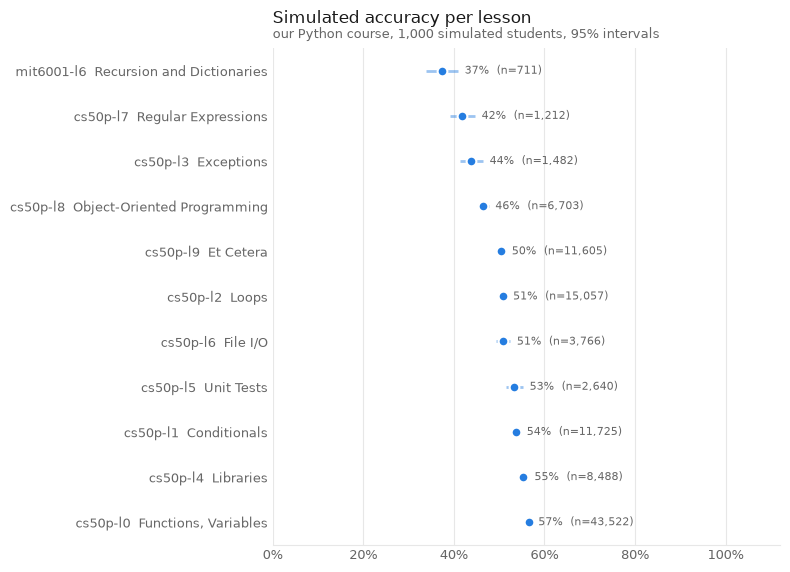

,lesson_name,n,accuracy,low,high
0,mit6001-l6 Recursion and Dictionaries,711,0.373,0.338,0.409
1,cs50p-l7 Regular Expressions,1212,0.418,0.391,0.446
2,cs50p-l3 Exceptions,1482,0.439,0.414,0.464
3,cs50p-l8 Object-Oriented Programming,6703,0.465,0.453,0.477
4,cs50p-l9 Et Cetera,11605,0.504,0.495,0.513
5,cs50p-l2 Loops,15057,0.508,0.500,0.516
6,cs50p-l6 File I/O,3766,0.508,0.492,0.524
7,cs50p-l5 Unit Tests,2640,0.533,0.514,0.552
8,cs50p-l1 Conditionals,11725,0.537,0.528,0.546
9,cs50p-l4 Libraries,8488,0.552,0.542,0.563


INSIGHT: In the simulation the lowest accuracy is in mit6001-l6 (37%); this reflects our simulator's rules, so it tests the pipeline, not real students.


In [3]:
by_lesson = eda.accuracy_by(sim, "lesson")
by_lesson["lesson_name"] = by_lesson["lesson"] + "  " + by_lesson["lesson"].map(lesson_title)
fig = eda.dot_plot(by_lesson, "lesson_name", "Simulated accuracy per lesson",
                   "our Python course, 1,000 simulated students, 95% intervals")
save(fig, "1_sim_accuracy_per_lesson")
display(by_lesson[["lesson_name", "n", "accuracy", "low", "high"]])
worst = by_lesson.iloc[0]
insight("1 accuracy (simulated)",
        f"In the simulation the lowest accuracy is in {worst['lesson']} ({worst['accuracy']:.0%}); "
        f"this reflects our simulator's rules, so it tests the pipeline, not real students.")

## 2. Learning curves: do students get better with practice?

A **learning curve** plots accuracy against the **attempt number** on a skill (1st try, 2nd try, ...).
If practice works, the curve goes **up**.

**The trap: who is still in the data?** Think of a marathon. The average pace of the runners
at kilometre 40 tells you about the people *still running*, not about how anyone's pace changed.
ASSISTments has a stopping rule: a student is done with a skill after **3 correct answers in a row**.
So strong students leave early, and the students left at attempt 8 are the weaker ones.

The fix: draw the curve twice.
- **everyone**: all answers at each attempt (the crowd changes along the curve)
- **same students**: only students who made at least 8 attempts (the crowd is fixed)

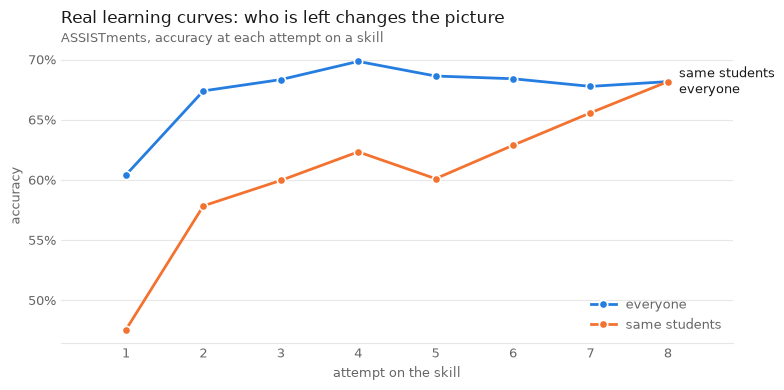

,attempt,accuracy_everyone,n_everyone,accuracy_same_students,n_same_students
0,1,0.604,42995,0.476,10988
1,2,0.674,31995,0.578,10988
2,3,0.683,25500,0.600,10988
3,4,0.698,22244,0.623,10988
4,5,0.686,18635,0.601,10988
5,6,0.684,15404,0.629,10988
6,7,0.678,13003,0.656,10988
7,8,0.682,10988,0.682,10988


first-attempt accuracy: students who needed 8+ attempts 48%, students who stopped earlier 65%
INSIGHT: Following the same students, accuracy rises 21 points from attempt 1 to 8; the everyone curve shows only 8 because strong students finish early and leave.


In [4]:
real_a = eda.add_attempt(real, "user_id", "skill")
curve_all = eda.learning_curve(real_a, 8, same_students=False)
curve_same = eda.learning_curve(real_a, 8, same_students=True)
fig = eda.line_chart({"everyone": curve_all, "same students": curve_same}, "attempt", "accuracy",
                     "Real learning curves: who is left changes the picture",
                     "ASSISTments, accuracy at each attempt on a skill", "attempt on the skill", "accuracy")
save(fig, "2_real_learning_curves")
display(curve_all.merge(curve_same, on="attempt", suffixes=("_everyone", "_same_students")))

stay = real_a[(real_a["attempt"] == 1) & (real_a["attempts_total"] >= 8)]["correct"].mean()
leave = real_a[(real_a["attempt"] == 1) & (real_a["attempts_total"] < 8)]["correct"].mean()
print(f"first-attempt accuracy: students who needed 8+ attempts {stay:.0%}, students who stopped earlier {leave:.0%}")
gain_same = curve_same["accuracy"].iloc[-1] - curve_same["accuracy"].iloc[0]
gain_all = curve_all["accuracy"].iloc[-1] - curve_all["accuracy"].iloc[0]
insight("2 learning curves (real)",
        f"Following the same students, accuracy rises {gain_same*100:.0f} points from attempt 1 to 8; "
        f"the everyone curve shows only {gain_all*100:.0f} because strong students finish early and leave.")

In [5]:
sim_a = eda.add_attempt(sim, "student_id", "concept")
sim_curve = eda.learning_curve(sim_a, 3, same_students=True)
display(sim_curve)
insight("2 learning curves (simulated)",
        f"Simulated students improve from {sim_curve['accuracy'].iloc[0]:.0%} to {sim_curve['accuracy'].iloc[1]:.0%} "
        f"between their 1st and 2nd question on a concept; the fixed path gives only 3 questions per concept, "
        f"so the curve is too short to show when students master a concept.")

,attempt,accuracy,n
0,1,0.478,35398
1,2,0.565,35398
2,3,0.558,35398


INSIGHT: Simulated students improve from 48% to 56% between their 1st and 2nd question on a concept; the fixed path gives only 3 questions per concept, so the curve is too short to show when students master a concept.


## 3. Dropout points: when and where do students quit?

Two ideas from **survival analysis** (originally from medicine and engineering):
- **still in the course**: the share of students who have not dropped out yet.
- **hazard**: the chance of quitting *this week*, given you made it to this week.
  A light bulb that has worked for 3 years: what is the chance it fails *this* month?

**Data limit:** ASSISTments has no dropout labels. We tried to reconstruct "quitting an assignment",
but the check below shows the reconstruction is broken, so this section uses the **simulated**
students only. Their weekly dropout was *calibrated* to the client's figure (45% before week 4),
so the week-by-week shape is ours, not a discovery.

In [6]:
# The check that ruled out real-data dropout: if sessions were complete, a "quit" without
# mastery would usually end on a WRONG answer. Here most end on a correct one.
s = real.sort_values(["user_id", "assignment_id", "order_id"]).groupby(["user_id", "assignment_id"])["correct"]
mastered = s.apply(lambda c: len(c) >= 3 and bool(c.iloc[-3:].all()))
last_right = s.last()
print(f"assignment sessions without 3-in-a-row: {(~mastered).sum():,}; "
      f"share of those ending on a CORRECT answer: {last_right[~mastered].mean():.0%}")
print("-> rows without a skill were removed in cleaning, so sessions are incomplete: not usable for dropout.")

assignment sessions without 3-in-a-row: 42,174; share of those ending on a CORRECT answer: 83%
-> rows without a skill were removed in cleaning, so sessions are incomplete: not usable for dropout.


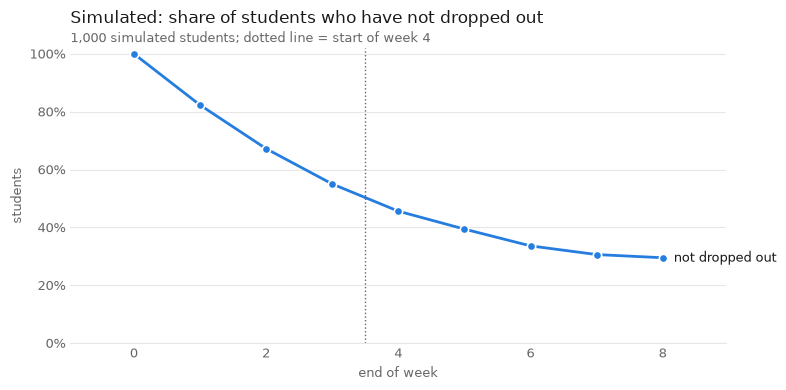

,week,at_risk,dropped,hazard,not_dropped_share
0,1,1000,177,0.177,0.823
1,2,823,151,0.183,0.672
2,3,672,122,0.182,0.550
3,4,550,94,0.171,0.456
4,5,448,62,0.138,0.394
5,6,330,58,0.176,0.336
6,7,207,30,0.145,0.306
7,8,122,11,0.090,0.295


INSIGHT: 45% of students are gone by the end of week 3; the weekly risk is about 18% each week in weeks 1-3 and falls to 14% on average afterwards, so retention work pays off most in the first three weeks.


In [7]:
surv = eda.survival(people, 8)
plot = pd.concat([pd.DataFrame({"week": [0], "not_dropped_share": [1.0]}), surv])
fig = eda.line_chart({"not dropped out": plot}, "week", "not_dropped_share",
                     "Simulated: share of students who have not dropped out",
                     "1,000 simulated students; dotted line = start of week 4",
                     "end of week", "students", marker_line=3.5, ylim=(0, 1.02))
save(fig, "3_sim_survival")
display(surv)
early, late = surv[surv["week"] <= 3]["hazard"], surv[surv["week"] >= 4]["hazard"]
insight("3 dropout (simulated)",
        f"{1 - surv.loc[surv['week'] == 3, 'not_dropped_share'].item():.0%} of students are gone by the end of week 3; "
        f"the weekly risk is {('about ' + format(early.mean(), '.0%') + ' each week') if early.max() - early.min() < 0.02 else (format(early.min(), '.0%') + '-' + format(early.max(), '.0%'))} in weeks 1-3 and falls to {late.mean():.0%} on average "
        f"afterwards, so retention work pays off most in the first three weeks.")

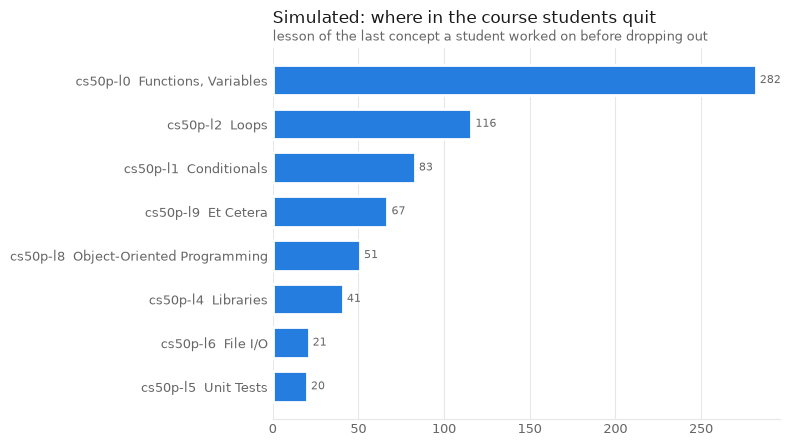

,lesson,dropouts,lesson_name,share_of_dropouts,share_of_course
0,cs50p-l0,282,"cs50p-l0 Functions, Variables",0.414,0.262
1,cs50p-l2,116,cs50p-l2 Loops,0.170,0.138
2,cs50p-l1,83,cs50p-l1 Conditionals,0.122,0.092
3,cs50p-l9,67,cs50p-l9 Et Cetera,0.098,0.200
4,cs50p-l8,51,cs50p-l8 Object-Oriented Programming,0.075,0.092
5,cs50p-l4,41,cs50p-l4 Libraries,0.060,0.092
6,cs50p-l6,21,cs50p-l6 File I/O,0.031,0.046
7,cs50p-l5,20,cs50p-l5 Unit Tests,0.029,0.031


INSIGHT: 41% of dropouts happen in cs50p-l0 (Functions, Variables), which is 26% of the course: 1.6x its size, so the first lesson needs extra support.


In [8]:
where = eda.dropout_position(sim, people, lesson_of)
where["lesson_name"] = where["lesson"] + "  " + where["lesson"].map(lesson_title)
path_share = pd.Series(lesson_of).value_counts(normalize=True)   # fixed path: 3 questions per concept
where["share_of_dropouts"] = where["dropouts"] / where["dropouts"].sum()
where["share_of_course"] = where["lesson"].map(path_share)
fig = eda.bar_chart(where, "lesson_name", "dropouts", "Simulated: where in the course students quit",
                    "lesson of the last concept a student worked on before dropping out")
save(fig, "3_sim_dropout_by_lesson")
display(where)
top = where.iloc[0]
ratio = top["share_of_dropouts"] / top["share_of_course"]
insight("3 dropout position (simulated)",
        f"{top['share_of_dropouts']:.0%} of dropouts happen in {top['lesson']} ({lesson_title[top['lesson']]}), "
        f"which is {top['share_of_course']:.0%} of the course"
        + (f": {ratio:.1f}x its size, so the first lesson needs extra support." if ratio > 1.2
           else ": about its size, so this lesson is not unusually risky."))

## 4. Hardest concepts: which are *really* the hardest?

Ranking by accuracy is a start, but two cautions:
1. **Overlapping intervals.** If two skills' 95% intervals overlap, we cannot say which is harder.
2. **Who attempts it.** A skill only strong students reach looks easier than it is (selection).
   In the simulation we know the *true* difficulty, so we can measure how well accuracy reflects it.

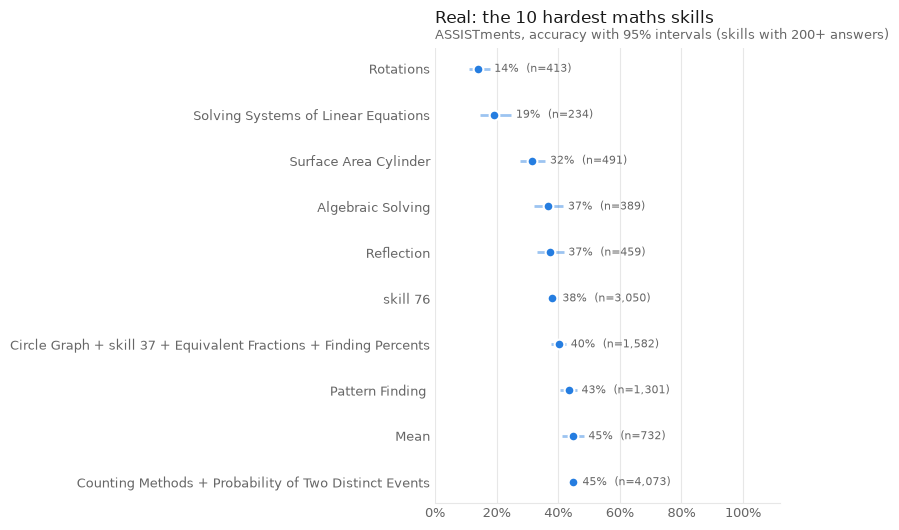

,skill_name,n,accuracy,low,high
0,Rotations,413,0.140,0.110,0.177
1,Solving Systems of Linear Equations,234,0.192,0.147,0.248
2,Surface Area Cylinder,491,0.316,0.276,0.358
3,Algebraic Solving,389,0.368,0.321,0.417
4,Reflection,459,0.373,0.330,0.418
5,skill 76,3050,0.381,0.364,0.398
6,Circle Graph + skill 37 + Equivalent Fractions...,1582,0.401,0.378,0.426
7,Pattern Finding,1301,0.434,0.407,0.461
8,Mean,732,0.447,0.411,0.483
9,Counting Methods + Probability of Two Distinct...,4073,0.448,0.433,0.464


INSIGHT: 'Rotations' is the hardest skill (14% correct), but its interval overlaps 'Solving Systems of Linear Equations', so treat the top two as tied.


In [9]:
hardest = skills.head(10)
fig = eda.dot_plot(hardest, "skill_name", "Real: the 10 hardest maths skills",
                   "ASSISTments, accuracy with 95% intervals (skills with 200+ answers)")
save(fig, "4_real_hardest_skills")
display(hardest[["skill_name", "n", "accuracy", "low", "high"]])
sure = eda.separable(hardest.iloc[0], hardest.iloc[1])
insight("4 hardest (real)",
        f"'{hardest.iloc[0]['skill_name']}' is the hardest skill ({hardest.iloc[0]['accuracy']:.0%} correct)"
        + (" and clearly harder than the next one (intervals do not overlap)." if sure
           else f", but its interval overlaps '{hardest.iloc[1]['skill_name']}', so treat the top two as tied."))

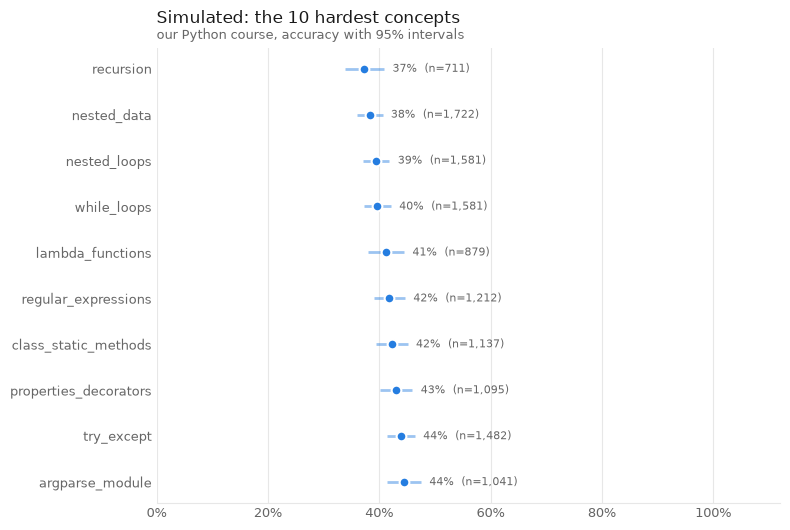

,concept,n,accuracy,low,high,true_difficulty
0,recursion,711,0.373,0.338,0.409,0.360
1,nested_data,1722,0.383,0.360,0.406,0.398
2,nested_loops,1581,0.394,0.370,0.418,0.439
3,while_loops,1581,0.397,0.373,0.421,0.108
4,lambda_functions,879,0.412,0.380,0.445,0.524
5,regular_expressions,1212,0.418,0.391,0.446,0.243
6,class_static_methods,1137,0.422,0.394,0.451,0.160
7,properties_decorators,1095,0.430,0.401,0.460,0.477
8,try_except,1482,0.439,0.414,0.464,0.077
9,argparse_module,1041,0.445,0.415,0.475,0.196


INSIGHT: Observed accuracy tracks the TRUE difficulty we planted closely (rank correlation -0.82; -1 = perfect): a fair first ranking, but accuracy also depends on who reached the concept, which Day 2's IRT separates out.


In [10]:
concepts = eda.accuracy_by(sim, "concept")
true_b = qtruth.groupby("concept")["truth_b"].mean()
concepts["true_difficulty"] = concepts["concept"].map(true_b)
rho = concepts["accuracy"].corr(concepts["true_difficulty"], method="spearman")
fig = eda.dot_plot(concepts.head(10), "concept", "Simulated: the 10 hardest concepts",
                   "our Python course, accuracy with 95% intervals")
save(fig, "4_sim_hardest_concepts")
display(concepts.head(10)[["concept", "n", "accuracy", "low", "high", "true_difficulty"]])
strength = "closely" if rho <= -0.7 else "only partly" if rho <= -0.4 else "poorly"
insight("4 hardest (simulated)",
        f"Observed accuracy tracks the TRUE difficulty we planted {strength} (rank correlation {rho:.2f}; -1 = perfect): "
        f"a fair first ranking, but accuracy also depends on who reached the concept, which Day 2's IRT separates out.")

## Summary of insights

In [11]:
summary = pd.DataFrame(INSIGHTS)
summary.to_csv(FIG_DIR / "insights.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(summary)

,section,insight
0,1 accuracy (real),"15 of 112 maths skills are answered correctly less than half the time, and the middle half of skills sits between 59% and 76%: skills differ a lot in difficulty, so equal practice per skill is likely too much for some and too little for others."
1,1 accuracy (simulated),"In the simulation the lowest accuracy is in mit6001-l6 (37%); this reflects our simulator's rules, so it tests the pipeline, not real students."
2,2 learning curves (real),"Following the same students, accuracy rises 21 points from attempt 1 to 8; the everyone curve shows only 8 because strong students finish early and leave."
3,2 learning curves (simulated),"Simulated students improve from 48% to 56% between their 1st and 2nd question on a concept; the fixed path gives only 3 questions per concept, so the curve is too short to show when students master a concept."
4,3 dropout (simulated),"45% of students are gone by the end of week 3; the weekly risk is about 18% each week in weeks 1-3 and falls to 14% on average afterwards, so retention work pays off most in the first three weeks."
5,3 dropout position (simulated),"41% of dropouts happen in cs50p-l0 (Functions, Variables), which is 26% of the course: 1.6x its size, so the first lesson needs extra support."
6,4 hardest (real),"'Rotations' is the hardest skill (14% correct), but its interval overlaps 'Solving Systems of Linear Equations', so treat the top two as tied."
7,4 hardest (simulated),"Observed accuracy tracks the TRUE difficulty we planted closely (rank correlation -0.82; -1 = perfect): a fair first ranking, but accuracy also depends on who reached the concept, which Day 2's IRT separates out."
